## SUPPORT VECTOR MACHINE

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from warnings import filterwarnings 
filterwarnings("ignore")

In [2]:
df =  pd.read_csv(r"C:\Users\deytu\Desktop\study\EXCELR\Assignment\Data and Docs\Pharma_Industry.csv")
df

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
0,-0.128538,0.303280,-1.881849,0.258286,-0.792011,1
1,-1.846188,2.865142,-0.929511,2.866786,-0.719447,1
2,-1.252393,-1.541613,0.363632,-0.325370,0.191314,0
3,1.992515,-1.142779,-0.766657,0.975286,-0.823355,1
4,0.377100,0.538410,-0.029263,1.896015,-0.960130,1
...,...,...,...,...,...,...
495,-1.553759,0.506938,0.817890,-0.661245,-1.345393,0
496,0.551476,1.714321,0.340589,1.712558,-0.496315,1
497,-1.072743,-0.221137,0.239247,1.112924,-0.285838,1
498,1.661259,0.245759,-0.457096,0.633355,0.657413,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Drug Dosage (mg)                500 non-null    float64
 1   Systolic Blood Pressure (mmHg)  500 non-null    float64
 2   Heart Rate (BPM)                500 non-null    float64
 3   Liver Toxicity Index (U/L)      500 non-null    float64
 4   Blood Glucose Level (mg/dL)     500 non-null    float64
 5   Drug Response                   500 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 23.6 KB


In [4]:
df.describe()

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.0000
mean,-0.037761,0.214957,0.062871,0.054398,-0.171863,0.5200
std,0.979891,1.247567,0.971978,0.986001,0.983765,0.5001
min,-3.019512,-3.773897,-2.940389,-3.401277,-3.110431,0.0000
25%,-0.642003,-0.565168,-0.648157,-0.586085,-0.797715,0.0000
50%,-0.019340,0.201532,0.027732,-0.065661,-0.108106,1.0000
75%,0.641151,0.951375,0.710774,0.633914,0.513555,1.0000
max,2.949094,4.111751,3.193108,3.373269,2.518023,1.0000


## Observation 
- All predictor variables appear to have been standardized (mean ≈ 0 and standard deviation ≈ 1).
- No null values are present
- The target variable is well balanced (52% positive responses vs. 48% negative responses)

## Visualisation  

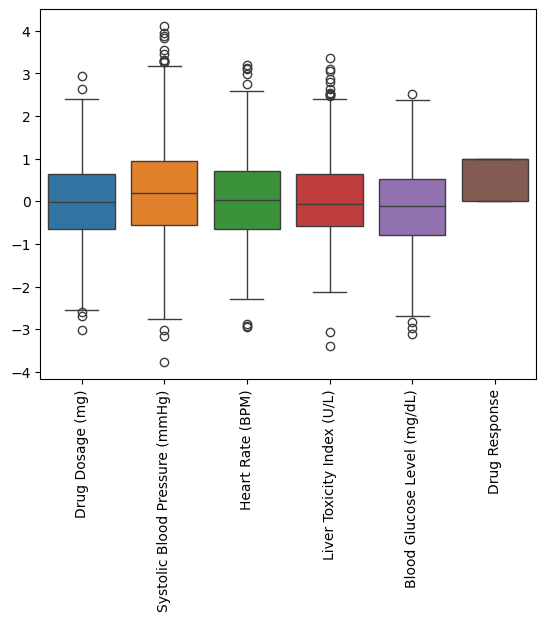

In [5]:
sns.boxplot(df)
plt.xticks(rotation = 90)
plt.show()

In [6]:
### since the data is already standardized we would avoid handling of the outliers foe now and will consider it after testing our model 


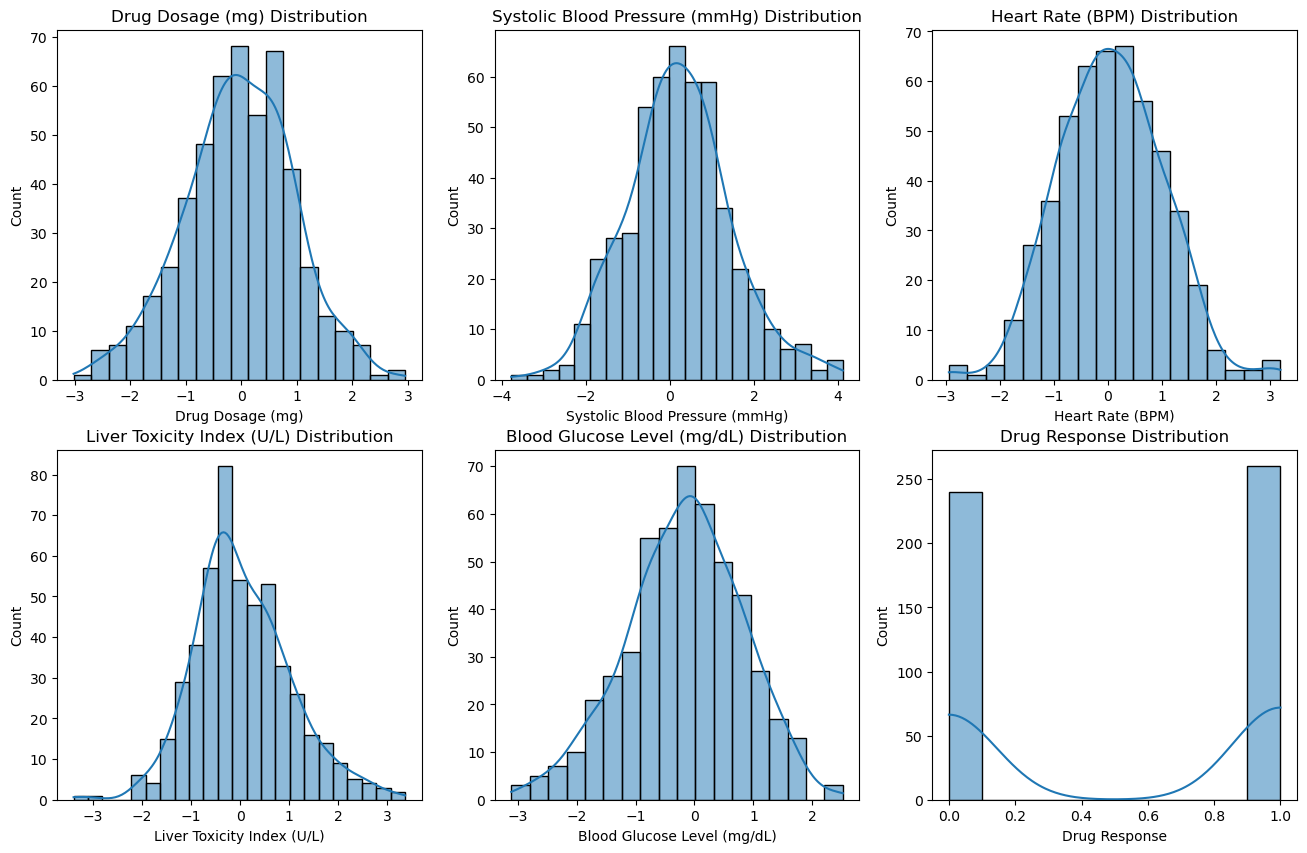

In [7]:
## Histplot
columns = ["Drug Dosage (mg)", "Systolic Blood Pressure (mmHg)","Heart Rate (BPM)", "Liver Toxicity Index (U/L)", "Blood Glucose Level (mg/dL)", 
           "Drug Response"]
fig , axes = plt.subplots(2,3 , figsize=(16,10))
axes = axes.flatten()
for i, col in enumerate(columns):
    sns.histplot(data = df , x = col ,kde = True, ax = axes[i])
    axes[i].set_title(f"{col} Distribution")
plt.show()

## Observation 
- The histograms indicate that all continuous predictor variables are approximately normally distributed and centered around zero, suggesting successful standardization of the data.
- Most variables exhibit only mild skewness and contain a small number of extreme observations.
- The target variable is well balanced, making the dataset suitable for classification modeling without concerns about class imbalance.

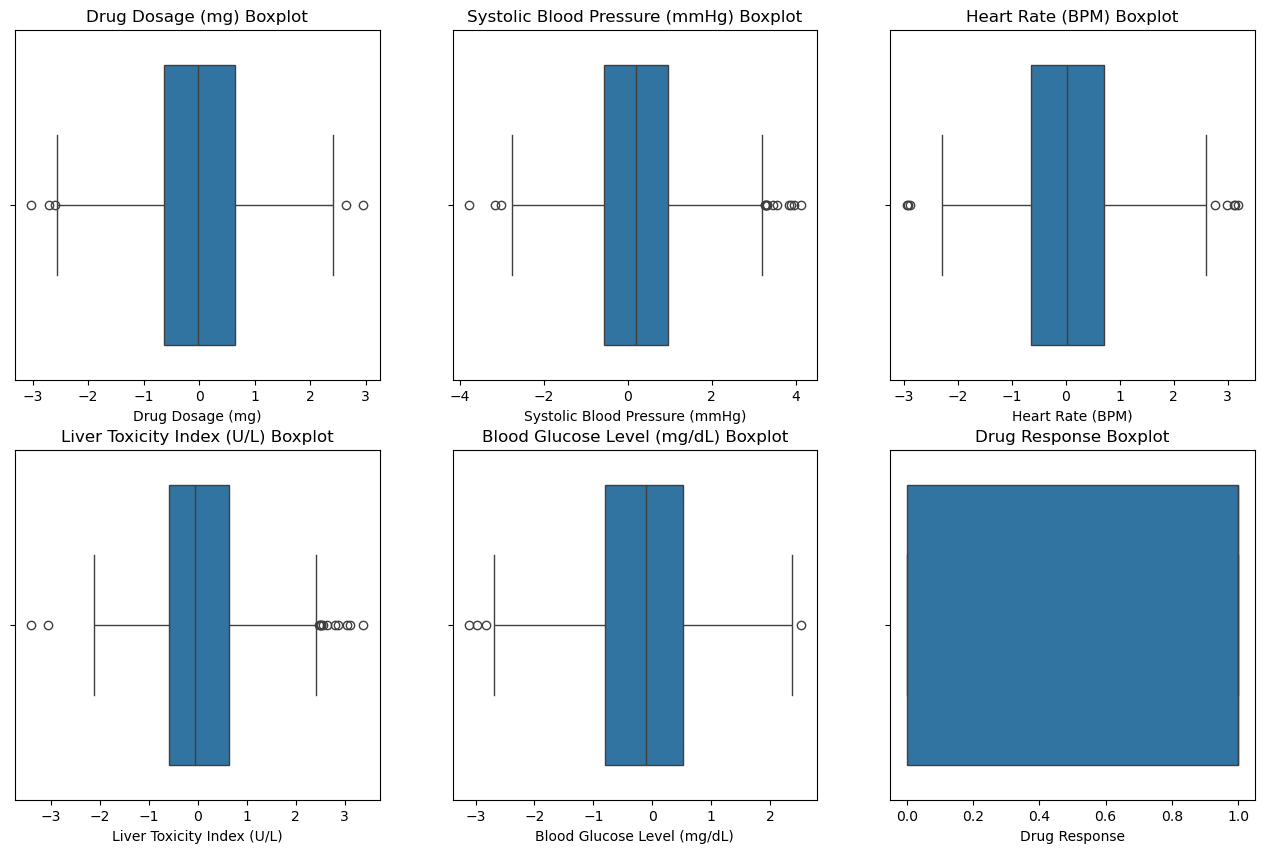

In [8]:
## Histplot
columns = ["Drug Dosage (mg)", "Systolic Blood Pressure (mmHg)","Heart Rate (BPM)", "Liver Toxicity Index (U/L)", "Blood Glucose Level (mg/dL)", 
           "Drug Response"]
fig , axes = plt.subplots(2,3 , figsize=(16,10))
axes = axes.flatten()
for i, col in enumerate(columns):
    sns.boxplot(data = df , x = col , ax = axes[i])
    axes[i].set_title(f"{col} Boxplot")
plt.show()

In [9]:
df.corr()

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
Drug Dosage (mg),1.000000,0.090618,0.040571,0.128127,0.012434,0.043457
Systolic Blood Pressure (mmHg),0.090618,1.000000,-0.039195,0.283672,0.037228,0.305226
Heart Rate (BPM),0.040571,-0.039195,1.000000,0.005818,0.049897,-0.009715
Liver Toxicity Index (U/L),0.128127,0.283672,0.005818,1.000000,0.229474,0.434722
Blood Glucose Level (mg/dL),0.012434,0.037228,0.049897,0.229474,1.000000,0.169342
Drug Response,0.043457,0.305226,-0.009715,0.434722,0.169342,1.000000


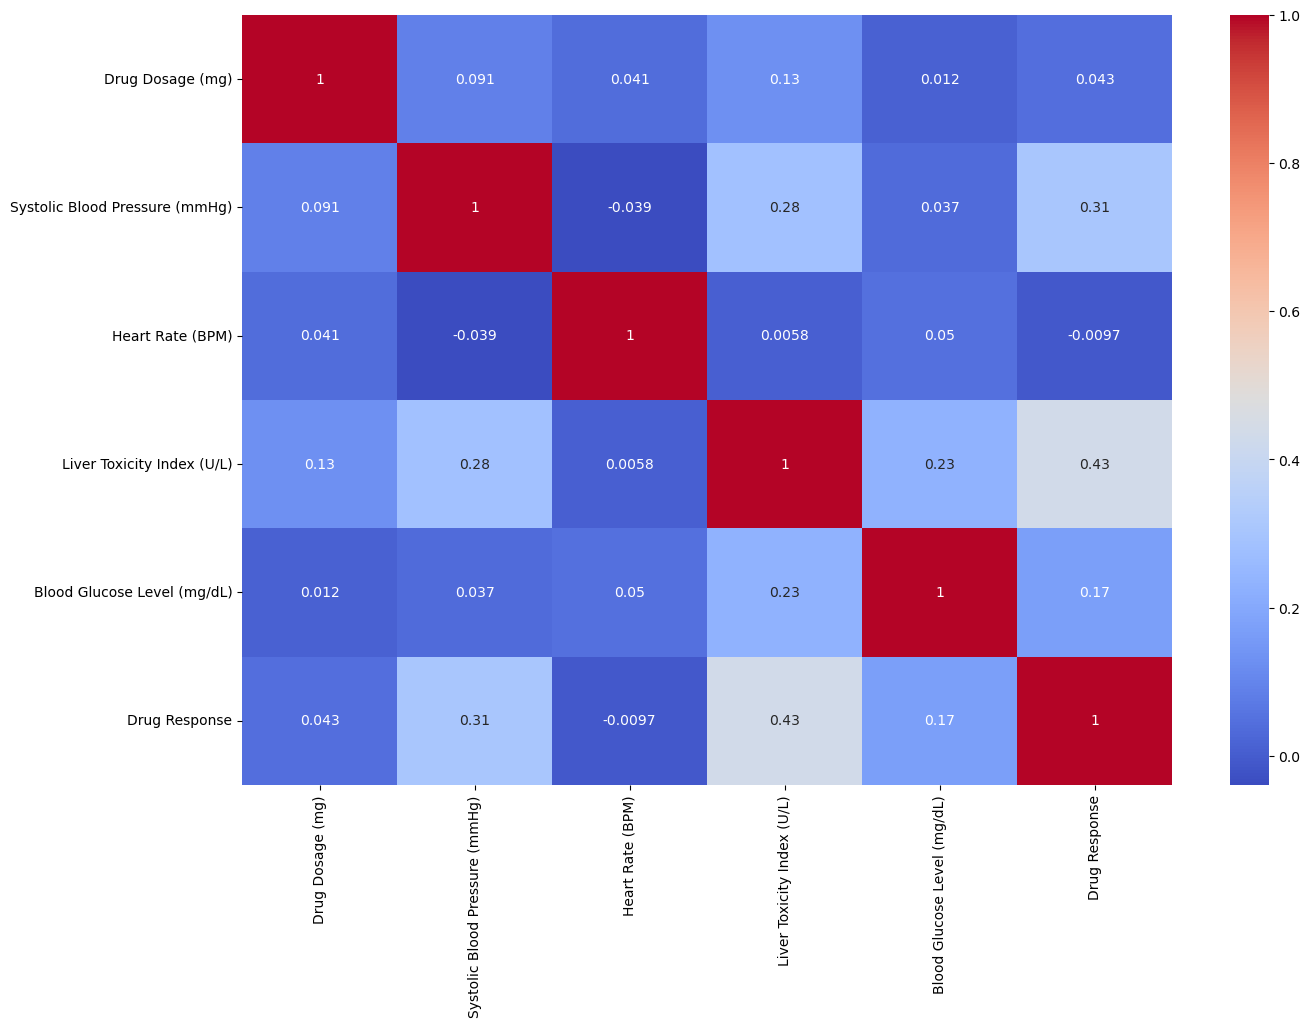

In [10]:
plt.figure(figsize =(15,10))
sns.heatmap(df.corr(numeric_only = True) , annot = True , cmap = 'coolwarm' )
plt.show()

## Observation 
- The correlation analysis indicates that Liver Toxicity Index and Systolic Blood Pressure are the most important variables associated with Drug Response.
- The predictor variables show generally weak intercorrelations, suggesting that each feature contributes unique information to the model.
- the absence of strong multicollinearity makes the dataset suitable for Support Vector Machine classification.

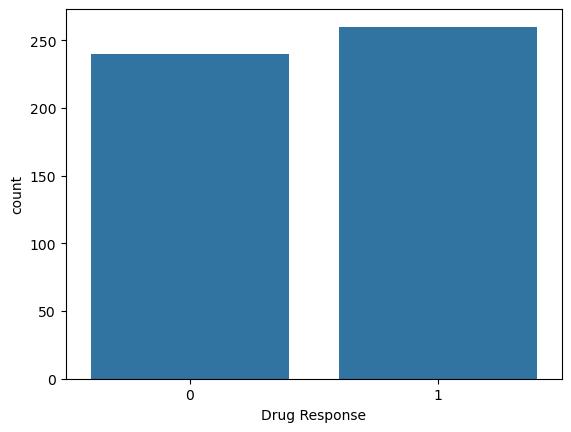

In [11]:
## Class Distribution check 
sns.countplot(x = 'Drug Response' , data = df )
plt.show()

In [12]:
##The target variable is well balanced with approximately 52% positive responses and 48% negative responses.

## Data Preprocessing 
Since all features in dataset are numerical and standardized, no categorical encoding was required.

In [13]:
### Train test split 
from sklearn.model_selection import train_test_split
X = df.drop(columns = "Drug Response", axis = 1)
y = df["Drug Response"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)




In [14]:
X_test

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL)
122,-1.522359,1.023210,1.112688,1.231781,-0.116187
161,-0.827590,0.132754,0.086144,0.283904,-0.037059
475,-0.026406,1.903488,0.280161,-0.694466,0.071306
405,0.436560,1.140270,0.903935,-1.607632,-0.995342
101,1.281644,-0.135718,0.557691,-0.912442,-0.524381
...,...,...,...,...,...
461,-0.054894,1.137944,0.285554,0.413840,0.543198
222,-1.105705,-0.397915,-0.214921,0.564633,-0.854457
263,-0.483061,-0.416244,0.146793,2.142717,-0.850920
162,1.032546,1.945074,1.126705,0.231548,0.730564


## SVM implementation 

In [15]:
from sklearn.svm import SVC
svm_model = SVC(kernel = 'rbf' , random_state = 42)

In [16]:
svm_model.fit(X_train,y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [17]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

y_pred = svm_model.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

Accuracy : 0.78
Precision: 0.7678571428571429
Recall   : 0.8269230769230769
F1 Score : 0.7962962962962963


### Observations
- The relatively high recall suggests that the model is effective at identifying patients who respond positively to the drug.
- The precision value indicates that the number of false positive predictions is reasonably low.
- The F1-score close to 80% reflects a well-balanced classification performance.
- Overall, the SVM model demonstrates good predictive capability and generalization on the test dataset

### Visualisation of results


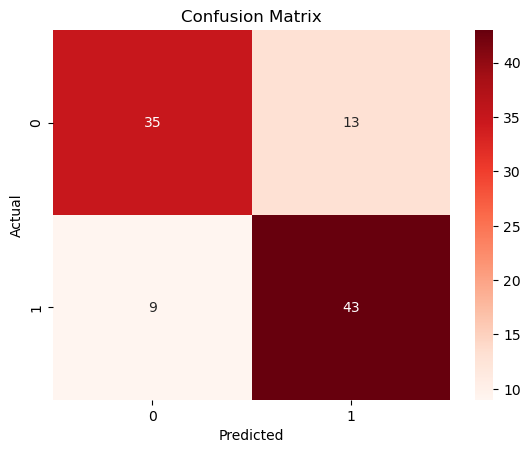

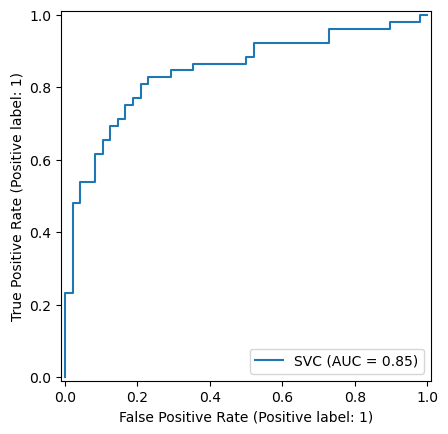

In [18]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test , y_pred)

sns.heatmap(cm , annot = True , cmap = 'Reds')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_estimator(svm_model , X_test , y_test)
plt.show()

### Observations
- The confusion matrix shows that the model is effective at identifying both positive and negative drug responses.
- The higher number of true positives (43) compared to false negatives (9) explains the strong recall value (82.69%).
- The ROC curve and AUC score confirm that the SVM classifier has good classification capability and can effectively distinguish between responders and non-responders.

## Parameter Tuning and Optimization

In [19]:

kernels = ['linear', 'poly', 'rbf']

for kernel in kernels:
    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(f"\nKernel: {kernel}")
    print("Accuracy :", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall   :", recall_score(y_test, y_pred))
    print("F1 Score :", f1_score(y_test, y_pred))


Kernel: linear
Accuracy : 0.72
Precision: 0.7608695652173914
Recall   : 0.6730769230769231
F1 Score : 0.7142857142857143

Kernel: poly
Accuracy : 0.72
Precision: 0.7727272727272727
Recall   : 0.6538461538461539
F1 Score : 0.7083333333333334

Kernel: rbf
Accuracy : 0.78
Precision: 0.7678571428571429
Recall   : 0.8269230769230769
F1 Score : 0.7962962962962963


In [20]:
C_values = [0.1, 1, 10, 100]

for c in C_values:
    model = SVC(kernel='rbf', C=c, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(f"\nC = {c}")
    print("Accuracy :", accuracy_score(y_test, y_pred))


C = 0.1
Accuracy : 0.75

C = 1
Accuracy : 0.78

C = 10
Accuracy : 0.73

C = 100
Accuracy : 0.73


### Observations
- Among the three kernels tested, the RBF kernel performed the best across all evaluation metrics.
- The experiment shows that the regularization parameter (C) has a significant impact on SVM performance. Among the values tested, C = 1 produced the highest accuracy (78%) and was selected as the optimal regularization parameter.
- we combine both RBF kernal and C value of 1 

In [26]:
c = 1
svm_final = SVC(kernel='rbf', C=c, random_state=42)
svm_final.fit(X_train, y_train)

y_pred = svm_final.predict(X_test)

In [27]:
print(f"\nKernel: {kernel}")
print(f"\nC ={c}")
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))


Kernel: rbf

C =1
Accuracy : 0.78
Precision: 0.7678571428571429
Recall   : 0.8269230769230769
F1 Score : 0.7962962962962963


### Conclusion
- The RBF kernel with C = 1 was selected as the final optimized SVM model because it achieved the highest overall performance among all the configurations tested.
- The model demonstrated good predictive capability with balanced precision, recall, and F1-score, making it suitable for accurately predicting drug response using the given clinical features.

## Analysis

### 1. Comparison of SVM Performance with Different Kernels

| Kernel | Accuracy | Precision | Recall | F1-Score |
|--------|---------:|----------:|-------:|---------:|
| Linear | 72% | 76.09% | 67.31% | 71.43% |
| Polynomial | 72% | 77.27% | 65.38% | 70.83% |
| RBF | 78% | 76.79% | 82.69% | 79.63% |

Observations:
- Linear kernel achieved 72% accuracy with moderate performance.
- Polynomial kernel had the highest precision but the lowest recall.
- RBF kernel achieved the highest accuracy, recall, and F1-score.
- RBF kernel was selected as the final model.


### 2. Strengths and Weaknesses of SVM

Strengths:
- Performs well on standardized data.
- Handles nonlinear relationships effectively using the RBF kernel.
- Achieved good classification performance with 78% accuracy.
- Suitable for balanced datasets.

Weaknesses:
- Sensitive to outliers.
- Performance depends on proper parameter tuning.
- Computational cost increases for larger datasets.


### 3. Practical Implications of SVM

- Can be used for disease diagnosis and drug response prediction.
- Helps classify patients based on clinical measurements.
- Supports medical decision-making and personalized treatment.
- Provides reliable predictions for real-world healthcare applications.